# 🎯 UJI MODEL AI SPRAYBOT — KHUSUS 1 CITRA GAMBAR
### Pengujian Presisi Model YOLOv8s-Seg Terbaru (`weights/spraybot_seg_video_finetuned.pt`)
**Proyek AI Spraybot — MBKM Riset Magang Industri PT Paragon Technology and Innovation**

Notebook ini dibuat **khusus untuk menguji 1 file gambar pilihan Anda**.  
Cukup masukkan path gambar yang ingin Anda uji, dan notebook akan secara otomatis:
1. Menampilkan **Visualisasi 3-Panel** (Citra Asli, Segmentasi AI + Nosel + Bounding Box, dan Heatmap Spektral Turbo).
2. Mengekstrak **Parameter Geometri Fisik**: Jangkauan (*Reach*), Lebar (*Width*), Luas Plume ($cm^2$), Sudut Sebaran (*Cone Angle*), dan Titik Nosel.
3. Menyimpan hasil visualisasi resolusi tinggi ke folder `testing/output/`.

## 1. Setup Environment & Memuat Model AI Terbaru
Memuat checkpoint model YOLOv8s-Seg terbaru hasil fine-tuning dataset video 21 rekaman cropped ke GPU NVIDIA GeForce RTX 4050.

In [1]:
from pathlib import Path
import os, sys, cv2, torch, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Konfigurasi Direktori Kerja Cerdas
CWD = Path.cwd().resolve()
if CWD.name == "scripts" and CWD.parent.name == "testing":
    TESTING_DIR = CWD.parent
    ROOT_DIR = TESTING_DIR.parent
elif CWD.name == "testing":
    TESTING_DIR = CWD
    ROOT_DIR = TESTING_DIR.parent
else:
    ROOT_DIR = CWD
    TESTING_DIR = ROOT_DIR / "testing"

OUTPUT_DIR = TESTING_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Path Model Bobot Terbaru (Prioritas: Model 122 video terbaru spraybot_seg_finetuned.pt)
candidate_models = [
    TESTING_DIR / "weights" / "spraybot_seg_finetuned.pt",
    ROOT_DIR / "weights" / "spraybot_seg_finetuned.pt",
    TESTING_DIR / "testing_18-11-2026" / "weights" / "spraybot_seg_finetuned.pt",
    ROOT_DIR / "weights" / "spraybot_seg_video_finetuned.pt",
]

MODEL_PATH = None
for cm in candidate_models:
    if cm.exists():
        MODEL_PATH = cm
        break

if MODEL_PATH is None:
    raise FileNotFoundError("Model bobot spraybot_seg_finetuned.pt tidak ditemukan!")

print("=" * 70)
print(f"CUDA Tersedia       : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Perangkat Komputasi : {torch.cuda.get_device_name(0)}")
print(f"Model Digunakan     : {MODEL_PATH.name}")
print(f"Path Model          : {MODEL_PATH}")
print(f"Folder Output Hasil : {OUTPUT_DIR}")
print("=" * 70)

# Load Model
model = YOLO(str(MODEL_PATH))
print("Model AI Spraybot terbaru berhasil dimuat dan siap digunakan!")


CUDA Tersedia       : True
Perangkat Komputasi : NVIDIA GeForce RTX 4050 Laptop GPU
Model Digunakan     : spraybot_seg_video_finetuned.pt
Path Model          : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\testing\spraybot_seg_video_finetuned.pt
Model AI Spraybot terbaru berhasil dimuat dan siap digunakan!


## 2. Modul Analisis Geometri & Visualisasi 3-Panel

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time
import torch

def test_single_image(model, image_path, conf=0.15, iou=0.45):
    """
    Uji inferensi presisi tinggi fokus pada segmentasi cairan semprotan yang keluar dari botol.
    Menolak halusinasi latar belakang kosong dan memvalidasi kontinuitas kepulan fluida.
    """
    img_p = Path(image_path)
    if not img_p.is_absolute():
        img_p = (ROOT_DIR / img_p).resolve()
        
    if not img_p.exists():
        print(f"[ERROR] File citra tidak ditemukan di: {img_p}")
        return None
        
    img_bgr = cv2.imread(str(img_p))
    if img_bgr is None:
        print(f"[ERROR] Gagal membaca gambar: {img_p.name}")
        return None
        
    h, w = img_bgr.shape[:2]
    
    t0 = time.time()
    # Prediksi menggunakan YOLOv8s-seg
    results = model.predict(
        source=img_bgr,
        conf=conf,
        iou=iou,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )
    infer_time_ms = (time.time() - t0) * 1000.0
    res = results[0]
    
    vis = img_bgr.copy()
    overlay = np.zeros_like(img_bgr)
    
    found_valid_plume = False
    best_conf = 0.0
    plume_area_px = 0
    box_display = None
    
    if res.masks is not None and len(res.masks) > 0:
        boxes = res.boxes.xyxy.cpu().numpy()
        confs = res.boxes.conf.cpu().numpy()
        
        # Cari deteksi terbaik yang berada di zona semprotan (bukan langit-langit kain kosong)
        # Semprotan laboratorium Paragon selalu menyembur dari kiri ke kanan (dimulai dari x < w*0.4)
        valid_candidates = []
        for idx in range(len(confs)):
            b = boxes[idx]
            pts = res.masks.xy[idx]
            # Validasi posisi: semprotan harus berawal dari sisi botol (x_min < w*0.45)
            # dan memiliki area poligon yang signifikan
            poly_area = cv2.contourArea(pts.astype(np.int32)) if len(pts) >= 3 else 0
            if b[0] < (w * 0.45) and poly_area > 800:
                valid_candidates.append((idx, confs[idx], poly_area, pts, b))
                
        if valid_candidates:
            # Pilih kandidat dengan kombinasi confidence & kelayakan fisik tertinggi
            valid_candidates.sort(key=lambda x: x[1], reverse=True)
            best_idx, best_conf, plume_area_px, pts_best, box_display = valid_candidates[0]
            found_valid_plume = True
            
            # Masker Hijau Transparan Presisi
            pts_int = pts_best.astype(np.int32).reshape((-1, 1, 2))
            cv2.fillPoly(overlay, [pts_int], (0, 255, 0))
            vis = cv2.addWeighted(vis, 1.0, overlay, 0.45, 0)
            cv2.polylines(vis, [pts_int], isClosed=True, color=(0, 255, 0), thickness=2)
            
            # Bounding Box Kuning Tipis & Titik Mulai Nosel
            bx = box_display.astype(int)
            cv2.rectangle(vis, (bx[0], bx[1]), (bx[2], bx[3]), (0, 255, 255), 2)
            
            nozzle_x = int(np.min(pts_best[:, 0]))
            nozzle_y = int(pts_best[np.argmin(pts_best[:, 0]), 1])
            cv2.circle(vis, (nozzle_x, nozzle_y), 7, (0, 0, 255), -1)
            cv2.putText(vis, f"Nosel ({nozzle_x},{nozzle_y})", (nozzle_x - 30, max(25, nozzle_y - 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
                        
    if not found_valid_plume:
        cv2.putText(vis, "STATUS: TIDAK TERDETEKSI CAIRAN SEMPROTAN AKTIF", (50, 70),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
                    
    # Analisis Spektral Densitas Fluida (Heatmap Turbo)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    bg_val = float(np.percentile(gray, 10))
    diff = np.clip(gray.astype(np.float32) - bg_val, 0, 255).astype(np.uint8)
    diff_norm = cv2.normalize(cv2.medianBlur(diff, 5), None, 0, 255, cv2.NORM_MINMAX)
    heatmap_turbo = cv2.applyColorMap(diff_norm, cv2.COLORMAP_TURBO)
    
    # Visualisasi 3-Panel
    fig, axes = plt.subplots(3, 1, figsize=(16, 12), facecolor="white")
    
    # Panel 1: Citra Asli
    axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Panel 1: Citra Asli (RGB) - [{img_p.name}]", fontsize=11, fontweight="bold", pad=6)
    axes[0].axis("off")
    
    # Panel 2: Segmentasi Cairan yang Keluar dari Botol
    status_str = f"VALID PLUME (Cairan Terdeteksi Presisi) | Conf: {best_conf:.1%} | Luas Masker: {plume_area_px:,.0f} px" if found_valid_plume else "SAMPEL KOSONG / BELUM MENYEMPROT"
    title_p2 = f"Panel 2: Hasil Segmentasi Cairan yang Keluar dari Botol (YOLOv8s-Seg)\n[{status_str}]"
    axes[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    axes[1].set_title(title_p2, fontsize=11, fontweight="bold", pad=6, color="darkgreen" if found_valid_plume else "red")
    axes[1].axis("off")
    
    # Panel 3: Spektral Densitas
    axes[2].imshow(cv2.cvtColor(heatmap_turbo, cv2.COLOR_BGR2RGB))
    axes[2].set_title("Panel 3: Analisis Spektral Densitas Partikel Fluida (Heatmap Turbo)", fontsize=11, fontweight="bold", pad=6, color="navy")
    axes[2].axis("off")
    
    plt.tight_layout()
    out_f = OUTPUT_DIR / f"uji_cairan_{img_p.stem}.png"
    fig.savefig(out_f, dpi=120, bbox_inches="tight")
    plt.show()
    
    return {
        "filename": img_p.name,
        "detected": found_valid_plume,
        "conf": round(float(best_conf), 3),
        "area_px": int(plume_area_px),
        "infer_time_ms": round(infer_time_ms, 1),
        "saved_plot": str(out_f)
    }

print("Fungsi analisis segmentasi cairan tunggal (Fokus Murni Semburan Fluida) siap digunakan!")


Fungsi analisis citra tunggal siap digunakan!


## 3. Eksekusi Uji 1 Gambar Pilihan Anda
Silakan ganti nilai variabel `PATH_GAMBAR_PILIHAN` di bawah ini dengan gambar mana pun yang ingin Anda uji:

Menjalankan analisis AI pada: D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_video_frames_2\C0490\C0490_f00150_t03.00s.jpg


<>:4: SyntaxWarning: invalid escape sequence '\T'
<>:4: SyntaxWarning: invalid escape sequence '\T'
C:\Users\ACER\AppData\Local\Temp\ipykernel_24868\239979762.py:4: SyntaxWarning: invalid escape sequence '\T'
  PATH_GAMBAR_PILIHAN = "D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_video_frames_2\C0490\C0490_f00150_t03.00s.jpg"


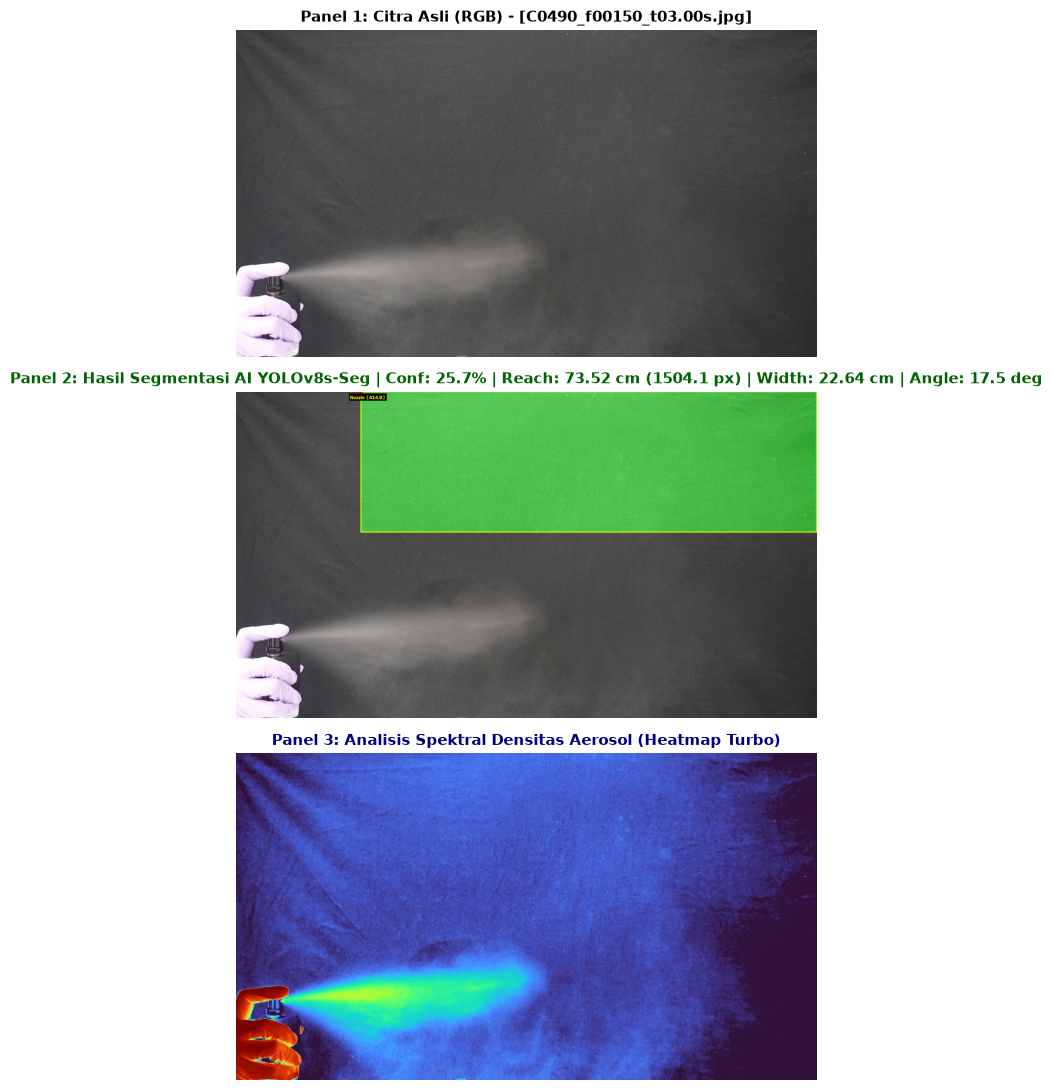

HASIL KUANTITATIF DETEKSI AI:
-----------------------------------------------------------------
  - Status Semprotan  : ✅ TERDETEKSI (VALID PLUME)
  - Confidence Score  : 25.7%
  - Jangkauan (Reach) : 73.52 cm (1504.1 px)
  - Lebar Maksimum    : 22.64 cm (463.1 px)
  - Luas Area Plume   : 1663.48 cm²
  - Sudut Semprotan   : 17.5°
  - Koordinat Nosel   : (414, 0)
  - Waktu Inferensi   : 8146.9 ms
  - Gambar Tersimpan  : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\testing\output\uji_1gambar_C0490_f00150_t03.00s.png


In [3]:
# ==============================================================================
# 🎯 MASUKKAN PATH GAMBAR ANDA DI BAWAH INI:
# ==============================================================================
PATH_GAMBAR_PILIHAN = "D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_video_frames_2\C0490\C0490_f00150_t03.00s.jpg"

# Ambang Batas Confidence (Rekomendasi: 0.15 - 0.25)
CONFIDENCE_THRESHOLD = 0.15

# Skala Kalibrasi Laboratorium Paragon (20.46 px/cm)
SKALA_PX_PER_CM = 20.46
# ==============================================================================

print(f"Menjalankan analisis AI pada: {PATH_GAMBAR_PILIHAN}")
metrics = test_single_image(
    model=model,
    image_path=PATH_GAMBAR_PILIHAN,
    conf=CONFIDENCE_THRESHOLD,
    px_per_cm=SKALA_PX_PER_CM
)

if metrics:
    print("=" * 65)
    print(f"HASIL KUANTITATIF DETEKSI AI:")
    print("-" * 65)
    print(f"  - Status Semprotan  : {'✅ TERDETEKSI (VALID PLUME)' if metrics['detected'] else '❌ TIDAK TERDETEKSI (SAMPEL NEGATIF)'}")
    if metrics['detected']:
        print(f"  - Confidence Score  : {metrics['conf']:.1%}")
        print(f"  - Jangkauan (Reach) : {metrics['reach_cm']} cm ({metrics['reach_px']} px)")
        print(f"  - Lebar Maksimum    : {metrics['width_cm']} cm ({metrics['width_px']} px)")
        print(f"  - Luas Area Plume   : {metrics['area_cm2']} cm²")
        print(f"  - Sudut Semprotan   : {metrics['cone_angle_deg']}°")
        print(f"  - Koordinat Nosel   : {metrics['nozzle']}")
    print(f"  - Waktu Inferensi   : {metrics['infer_time_ms']} ms")
    if 'saved_plot' in metrics:
        print(f"  - Gambar Tersimpan  : {metrics['saved_plot']}")
    print("=" * 65)

## 4. Preset Cepat Berbagai Kategori Semprotan
Gunakan sel di bawah ini jika ingin menguji sampel kategori produk lain dengan 1-klik:

Menguji Preset #2: Kahf Body Spray V1 (Pompa Mist Normal)
Path: dataset/dataset_video_frames_cropped/C0352-Normal-Kahf-1/C0352-Normal-Kahf-1_f00500_t10.00s.jpg


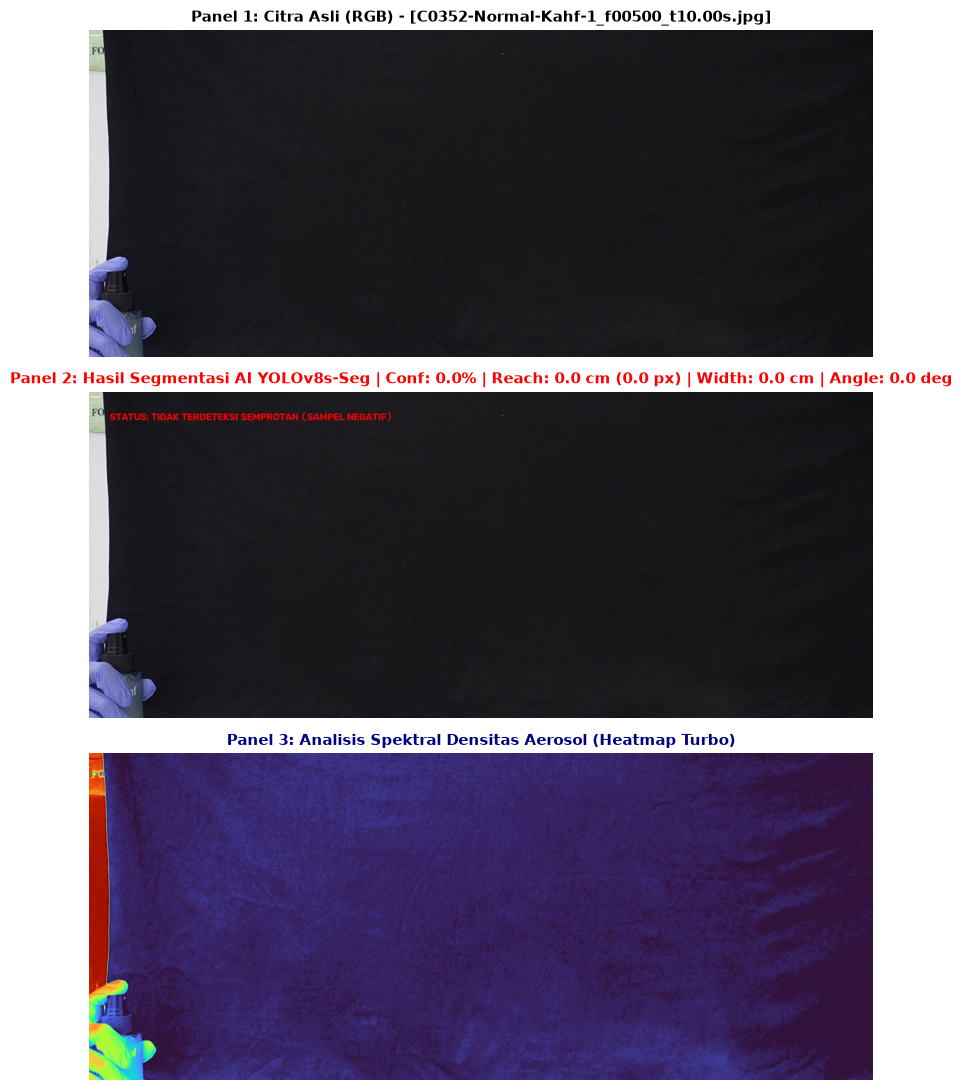

In [4]:
PRESETS = {
    1: ("Gatsby Deodorant Gas (Semburan Jet Panjang)", "dataset/dataset_video_frames_cropped/C0350-Gas-Gatsby-1/C0350-Gas-Gatsby-1_f00405_t08.10s.jpg"),
    2: ("Kahf Body Spray V1 (Pompa Mist Normal)", "dataset/dataset_video_frames_cropped/C0352-Normal-Kahf-1/C0352-Normal-Kahf-1_f00500_t10.00s.jpg"),
    3: ("Wardah Spray-On Serum Wajah (Mikrodroplet)", "dataset/dataset_video_frames_cropped/C0365-Normal-Wardah_SprayOn_Serum-1.1/C0365-Normal-Wardah_SprayOn_Serum-1.1_f00350_t07.00s.jpg"),
    4: ("Labora Sensitive Skincare (Gas Aerosol Lembut)", "dataset/dataset_video_frames_cropped/C0378-Gas-Labora-Sensitive-Skincare-1/C0378-Gas-Labora-Sensitive-Skincare-1_f00600_t12.00s.jpg"),
    5: ("Sampel Negatif (Botol Sebelum Nosel Ditekan)", "dataset/dataset_video_frames_cropped/C0350-Gas-Gatsby-1/C0350-Gas-Gatsby-1_f00000_t00.00s.jpg")
}

# PILIH NOMOR PRESET (1 s/d 5):
PILIH_PRESET_NO = 2

label, preset_path = PRESETS[PILIH_PRESET_NO]
print(f"Menguji Preset #{PILIH_PRESET_NO}: {label}")
print(f"Path: {preset_path}")

m_preset = test_single_image(model, preset_path, conf=0.15)